#### 1.Import the necessary libraries

In [451]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import RocCurveDisplay, roc_auc_score

In [5]:
os.getcwd()

'c:\\Users\\alvar\\Documents\\Github_Projects\\Bikes_Buyers\\Bike-Buyers'

In [7]:
df = pd.read_csv('Data/Ventas_Bicicletas.csv')
df.head()

,CustomerID,Title,FirstName,MiddleName,LastName,Suffix,AddressLine1,AddressLine2,City,StateProvinceName,...,MaritalStatus,HomeOwnerFlag,NumberCarsOwned,NumberChildrenAtHome,TotalChildren,YearlyIncome,LastUpdated,BikeBuyer,AvgMonthSpend,BikeBuyerText
0,21173,NaN,Chad,C,Yuan,NaN,7090 C. Mount Hood,NaN,Wollongong,New South Wales,...,M,1,3,0,1,81916,3/6/2017,1,50.97,YES
1,13249,NaN,Ryan,NaN,Perry,NaN,3651 Willow Lake Rd,NaN,Shawnee,British Columbia,...,M,1,2,1,2,81076,3/6/2017,1,53.11,YES
2,29350,NaN,Julia,NaN,Thompson,NaN,1774 Tice Valley Blvd.,NaN,West Covina,California,...,S,0,3,0,0,86387,3/6/2017,1,54.08,YES
3,13503,NaN,Theodore,NaN,Gomez,NaN,2103 Baldwin Dr,NaN,Liverpool,England,...,M,1,2,1,2,61481,3/6/2017,1,56.93,YES
4,22803,NaN,Marshall,J,Shan,NaN,Am Gallberg 234,NaN,Werne,Nordrhein-Westfalen,...,S,1,1,0,0,51804,3/6/2017,1,55.41,YES


In [10]:
df.shape

(18355, 27)

In [14]:
df['CountryRegionName'].head()

0         Australia
1            Canada
2     United States
3    United Kingdom
4           Germany
Name: CountryRegionName, dtype: str

We have 18.355 observations. the next steep is to keep remove the variables that add noise to the model e.g FirstName, MiddleName, LastName. This variables belongs to an individual level and we cannot make any type of generalization with the data.

In [19]:
var_to_remove = ['Title', 'FirstName', 'MiddleName', 'LastName', 'Suffix',
       'AddressLine1', 'AddressLine2', 'PostalCode', 'PhoneNumber','LastUpdated']

In [376]:
df_model = df.copy()
df_model.drop(columns = var_to_remove,inplace = True)
df_model.head()

,CustomerID,City,StateProvinceName,CountryRegionName,BirthDate,Education,Occupation,Gender,MaritalStatus,HomeOwnerFlag,NumberCarsOwned,NumberChildrenAtHome,TotalChildren,YearlyIncome,BikeBuyer,AvgMonthSpend,BikeBuyerText
0,21173,Wollongong,New South Wales,Australia,11/13/1987,Bachelors,Clerical,M,M,1,3,0,1,81916,1,50.97,YES
1,13249,Shawnee,British Columbia,Canada,7/21/1972,Partial College,Clerical,M,M,1,2,1,2,81076,1,53.11,YES
2,29350,West Covina,California,United States,11/9/1985,Bachelors,Clerical,F,S,0,3,0,0,86387,1,54.08,YES
3,13503,Liverpool,England,United Kingdom,10/18/1977,Partial College,Skilled Manual,M,M,1,2,1,2,61481,1,56.93,YES
4,22803,Werne,Nordrhein-Westfalen,Germany,2/5/1975,Partial College,Skilled Manual,M,S,1,1,0,0,51804,1,55.41,YES


Data Engeeniering 

In [377]:
# since we have the Birth date, c=we create age as a new variable
df_model['Age'] = round((pd.Timestamp.today()-pd.to_datetime(df_model['BirthDate'])).dt.days/365,2)
df_model['Age'].head()

0    39.04
1    54.36
2    41.05
3    49.11
4    51.81
Name: Age, dtype: float64

In [378]:
df_model.columns

Index(['CustomerID', 'City', 'StateProvinceName', 'CountryRegionName',
       'BirthDate', 'Education', 'Occupation', 'Gender', 'MaritalStatus',
       'HomeOwnerFlag', 'NumberCarsOwned', 'NumberChildrenAtHome',
       'TotalChildren', 'YearlyIncome', 'BikeBuyer', 'AvgMonthSpend',
       'BikeBuyerText', 'Age'],
      dtype='str')

The next step is plotting a series of bar charts which helps to see the relationship between
our target variable (BikeBuyer) and the dependent 

In [379]:
#(pd.crosstab(df_model['StateProvinceName'],df_model['BikeBuyer'])) \
#            .sort_values(by= 1, ascending=False)

In [380]:
# This function helps to reuse the barcharts and visualiza the relashinship
# bwtween the buy-nonbuy and the independent variables
def bar_plot_bikes(variable,dataframe):
    plot_data = round((pd.crosstab(dataframe[variable],dataframe['BikeBuyer'],normalize='index')) \
            .sort_values(by= 1, ascending=False),2)
    fig, ax = plt.subplots(figsize=(8, 4))
    res = ax.grouped_bar([plot_data[1], plot_data[0]],
            tick_labels=plot_data.index.to_list(),
            labels=['No buy','Buy'])
    for container in res.bar_containers:
        ax.bar_label(container, padding=0.5)

    label = variable
    # Add some text for labels, title, etc.
    ax.set_ylabel("Proportion of buy and non Buy")
    ax.set_title(f"Proportion of buy-nobuy by each {label}")
    ax.legend(loc='upper left', ncols=3)
    ax.set_ylim(0, 0.8)

    plt.show()


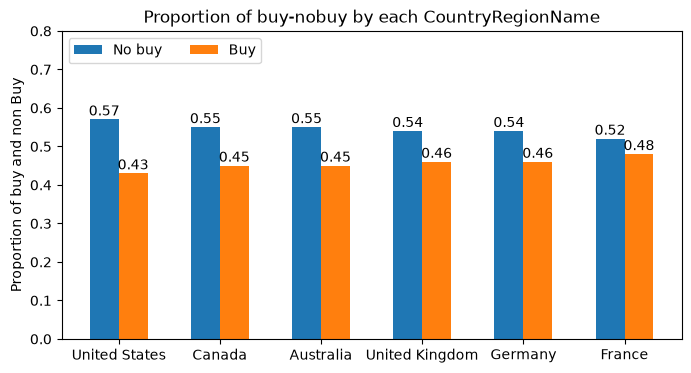

In [381]:
bar_plot_bikes(variable = 'CountryRegionName',dataframe=df_model)

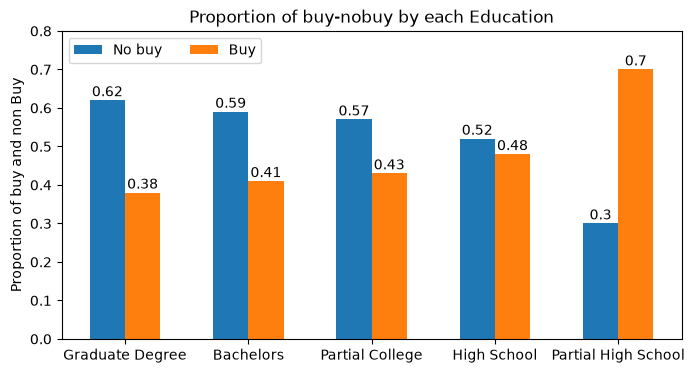

In [382]:
bar_plot_bikes(variable = 'Education',dataframe=df_model)

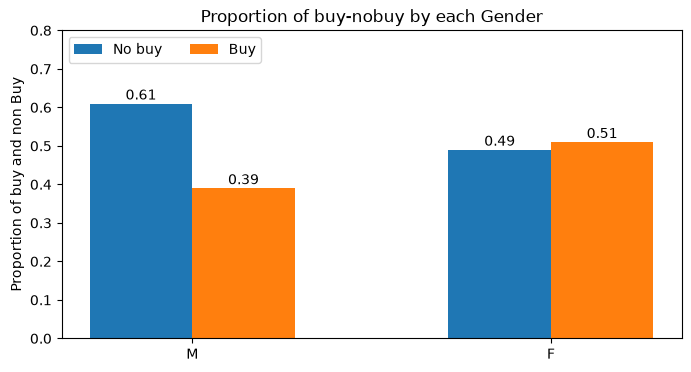

In [383]:
bar_plot_bikes(variable = 'Gender',dataframe=df_model)

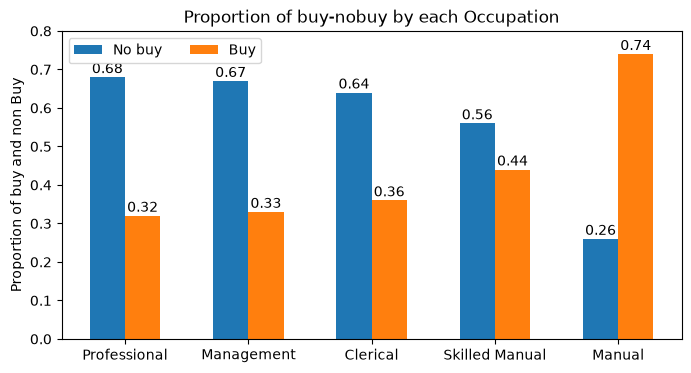

In [384]:
bar_plot_bikes(variable = 'Occupation',dataframe=df_model)

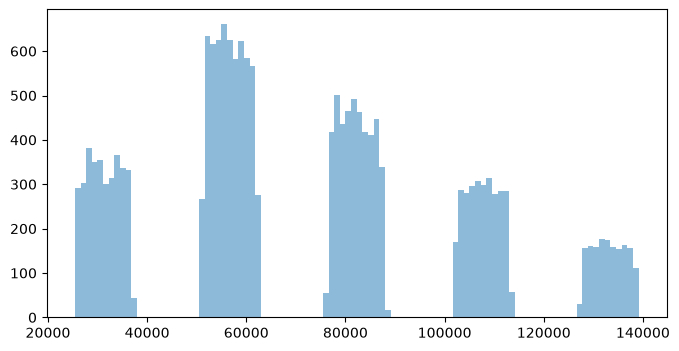

In [385]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_model['YearlyIncome'],bins= 100,alpha = 0.5)
plt.show()

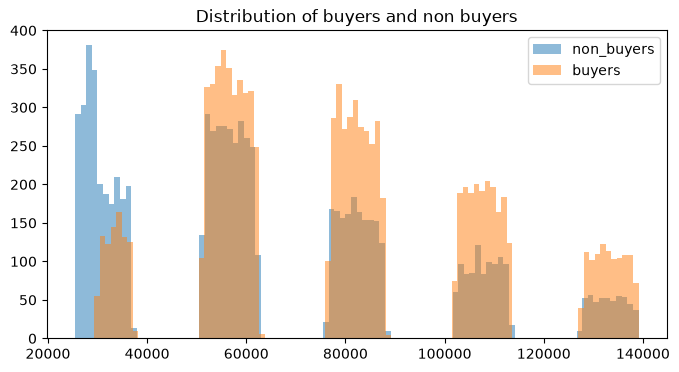

In [386]:
non_buyers =df_model.loc[(df_model['BikeBuyer'] == 0),'YearlyIncome']
buyers =df_model.loc[(df_model['BikeBuyer'] == 1),'YearlyIncome']

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(non_buyers,bins= 100,alpha = 0.5)
ax.hist(buyers,bins =100, alpha = 0.5)
ax.legend(['non_buyers','buyers'])
plt.title('Distribution of buyers and non buyers')
plt.show()


In [387]:
def Woe_IV_plot(variable,dataframe):
    plot_data = round((pd.crosstab(dataframe[variable],dataframe['BikeBuyer'],normalize='index')) \
                .sort_values(by= 1, ascending=False),2)
    plot_data['Woe'] = np.log(plot_data[0]/plot_data[1])
    plot_data['IV'] = (plot_data[0]-plot_data[1])*plot_data['Woe']
    InformatioValue = plot_data['IV'].sum().round(2)

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(plot_data.index.to_list(),plot_data['Woe'])
    ax.bar_label(bars, fmt='%.2f')
    ax.set_ylabel("Weight of evidence")
    plt.title(f"Information value = {InformatioValue}")

    plt.show()


In [388]:
df_model.columns

Index(['CustomerID', 'City', 'StateProvinceName', 'CountryRegionName',
       'BirthDate', 'Education', 'Occupation', 'Gender', 'MaritalStatus',
       'HomeOwnerFlag', 'NumberCarsOwned', 'NumberChildrenAtHome',
       'TotalChildren', 'YearlyIncome', 'BikeBuyer', 'AvgMonthSpend',
       'BikeBuyerText', 'Age'],
      dtype='str')

In [389]:
np.min(df_model['Age'])

np.float64(25.91)

In [390]:
df_model['AgeBracket'] = np.where((df_model['Age'] > 18)&(df_model['Age'] <=35),'18-35',
                                  np.where((df_model['Age'] > 36)&(df_model['Age'] <=45),'36-45',
                                           np.where((df_model['Age'] > 45)&(df_model['Age'] <=55),'46-55','+60')))

In [391]:
df_model['Gender'] = np.where(df_model['Gender'] == 'M',1,0)
df_model['MaritalStatus'] = np.where(df_model['MaritalStatus']== 'S',1,0)

In [392]:
df_model['MaritalStatus'].value_counts()

MaritalStatus
0    9945
1    8410
Name: count, dtype: int64

In [395]:
countries = pd.get_dummies(df_model['CountryRegionName'],prefix='Country',dtype=float)
bachelors = pd.get_dummies(df_model['Education'],prefix='Education',dtype=float)
occupation = pd.get_dummies(df_model['Occupation'],prefix='Occupation',dtype=float)
age_bracket = pd.get_dummies(df_model['AgeBracket'],prefix='Age',dtype=float)

df_model = pd.concat([df_model,countries,bachelors,occupation,age_bracket],axis=1)

In [396]:
df_model.head()

,CustomerID,City,StateProvinceName,CountryRegionName,BirthDate,Education,Occupation,Gender,MaritalStatus,HomeOwnerFlag,...,Education_Partial High School,Occupation_Clerical,Occupation_Management,Occupation_Manual,Occupation_Professional,Occupation_Skilled Manual,Age_+60,Age_18-35,Age_36-45,Age_46-55
0,21173,Wollongong,New South Wales,Australia,11/13/1987,Bachelors,Clerical,1,0,1,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,13249,Shawnee,British Columbia,Canada,7/21/1972,Partial College,Clerical,1,0,1,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,29350,West Covina,California,United States,11/9/1985,Bachelors,Clerical,0,1,0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,13503,Liverpool,England,United Kingdom,10/18/1977,Partial College,Skilled Manual,1,0,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,22803,Werne,Nordrhein-Westfalen,Germany,2/5/1975,Partial College,Skilled Manual,1,1,1,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [397]:
X_covariates = [ 'Gender', 'MaritalStatus',
    'HomeOwnerFlag', 'NumberCarsOwned', 'NumberChildrenAtHome',
    'TotalChildren', 'YearlyIncome', 'AvgMonthSpend', 
    'Country_Australia',
    'Country_Canada', 'Country_France', 'Country_Germany',
       'Country_United Kingdom', 'Country_United States',
       'Education_Bachelors', 'Education_Graduate Degree',
       'Education_High School', 'Education_Partial College',
       'Education_Partial High School', 'Occupation_Clerical',
       'Occupation_Management', 'Occupation_Manual', 'Occupation_Professional',
       'Occupation_Skilled Manual','CountryRegionName',
       'BirthDate', 'Education', 'Occupation','Age_18-35','Age_36-45','Age_46-55','Age_+60'
]

In [398]:
# Slipt the data in 80-20 %
X_train, X_test, y_train, y_test = train_test_split(
    df_model[X_covariates], df['BikeBuyer'], test_size=0.20, random_state=42)

In [399]:
training_data = pd.concat([X_train,y_train],axis=1)

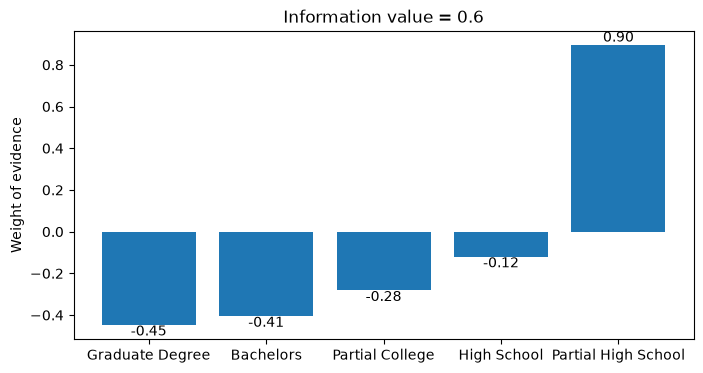

In [413]:
Woe_IV_plot('Education',training_data)

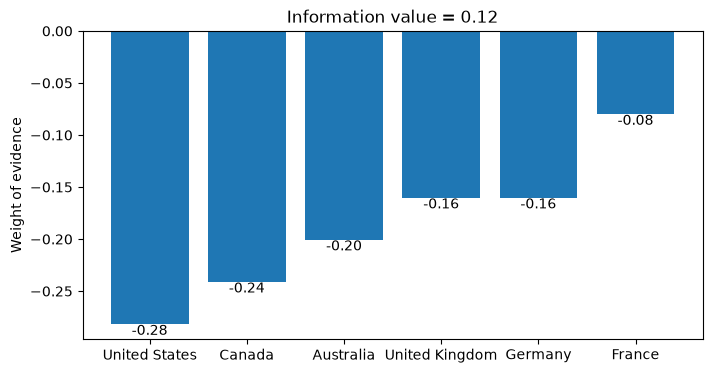

In [400]:
Woe_IV_plot('CountryRegionName',training_data)

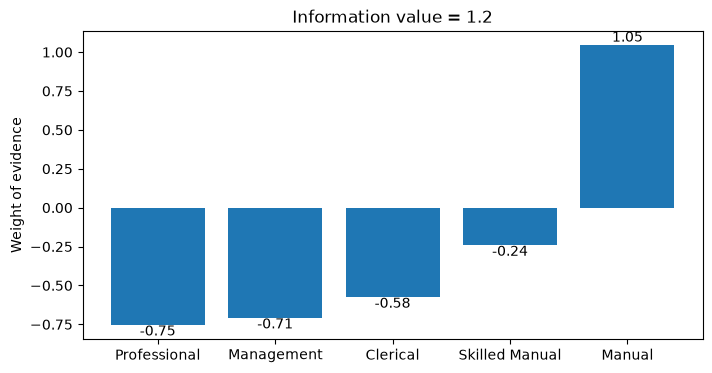

In [401]:
# An information value of 1.2 is really high sometimes considered suspicius. So we will
# Check the data if is there leackage
Woe_IV_plot('Occupation',training_data)

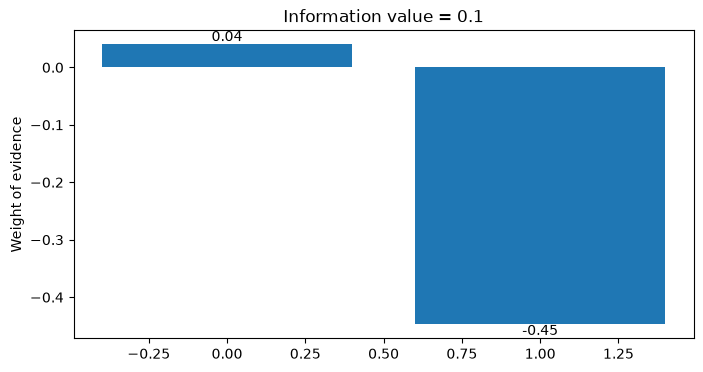

In [402]:
#there seems no predictive power for Gender
Woe_IV_plot('Gender',training_data)

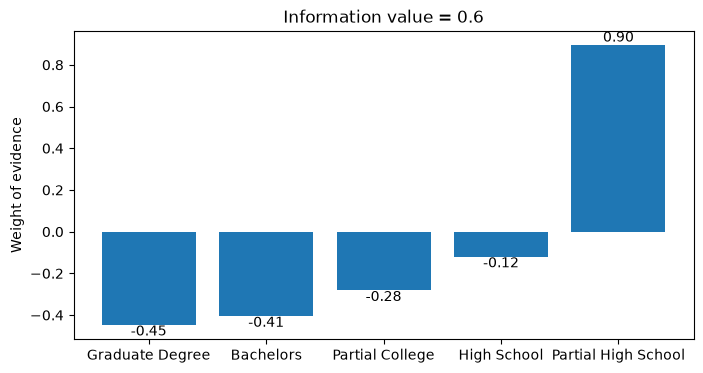

In [403]:
Woe_IV_plot('Education',training_data)

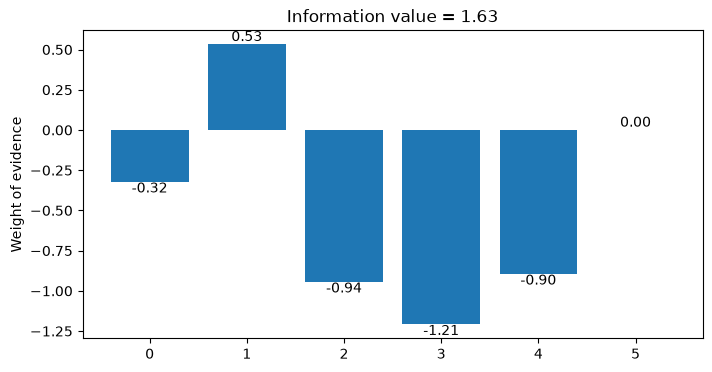

In [404]:
Woe_IV_plot('NumberCarsOwned',training_data)

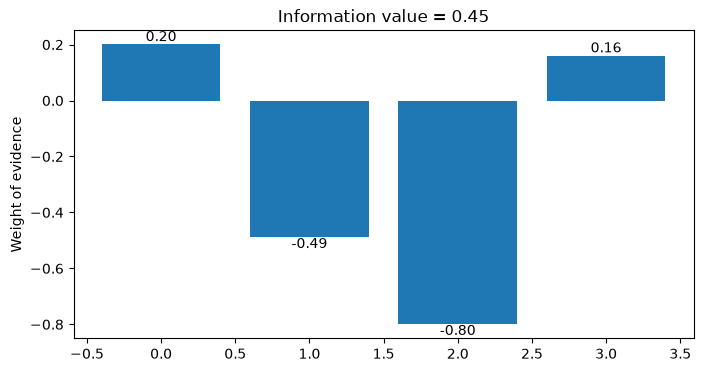

In [405]:
Woe_IV_plot('TotalChildren',training_data)

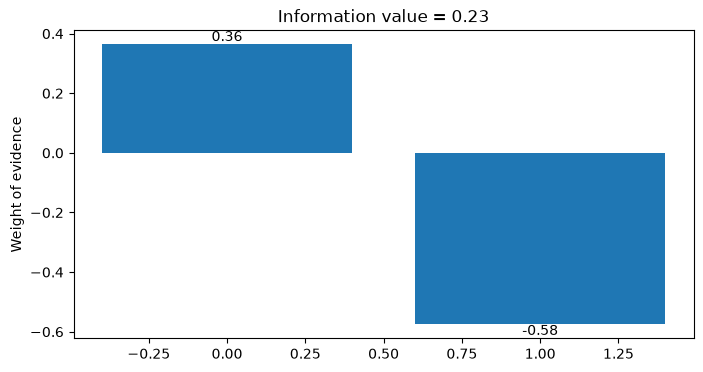

In [406]:
Woe_IV_plot('HomeOwnerFlag',training_data)

In [457]:
Woe_IV_plot('AgeBracket',training_data)

KeyError: 'AgeBracket'

In [ ]:
X_train.columns

Index(['Gender', 'MaritalStatus', 'HomeOwnerFlag', 'NumberCarsOwned',
       'NumberChildrenAtHome', 'TotalChildren', 'YearlyIncome',
       'AvgMonthSpend', 'AgeBracket', 'Country_Australia', 'Country_Canada',
       'Country_France', 'Country_Germany', 'Country_United Kingdom',
       'Country_United States', 'Education_Bachelors',
       'Education_Graduate Degree', 'Education_High School',
       'Education_Partial College', 'Education_Partial High School',
       'Occupation_Clerical', 'Occupation_Management', 'Occupation_Manual',
       'Occupation_Professional', 'Occupation_Skilled Manual',
       'CountryRegionName', 'BirthDate', 'Education', 'Occupation'],
      dtype='str')

In [415]:
X_covariates = ['Gender', 'MaritalStatus', 'HomeOwnerFlag', 'NumberCarsOwned',
       'NumberChildrenAtHome', 'TotalChildren', 'YearlyIncome',
       'AvgMonthSpend', 'Country_Australia', 'Country_Canada',
       'Country_Germany', 'Country_United Kingdom',
       'Country_United States', 'Education_Bachelors', 'Education_High School',
       'Education_Partial College', 'Education_Partial High School', 'Occupation_Management', 'Occupation_Manual',
       'Occupation_Professional', 'Occupation_Skilled Manual',
       'Age_18-35','Age_36-45','Age_46-55'
       ]

In [416]:
X_train[X_covariates].head()

,Gender,MaritalStatus,HomeOwnerFlag,NumberCarsOwned,NumberChildrenAtHome,TotalChildren,YearlyIncome,AvgMonthSpend,Country_Australia,Country_Canada,...,Education_High School,Education_Partial College,Education_Partial High School,Occupation_Management,Occupation_Manual,Occupation_Professional,Occupation_Skilled Manual,Age_18-35,Age_36-45,Age_46-55
10885,1,0,1,3,1,2,109111,61.48,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
7383,0,1,0,0,0,0,56577,49.70,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1571,0,0,1,1,0,0,133887,52.50,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
18061,0,0,1,2,0,2,58066,49.44,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
9888,0,0,1,2,0,3,108901,51.34,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


c:\Users\alvar\Anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression AUC: 0.7766
Random Forest AUC: 0.8555
Gradient Boosting AUC: 0.8780


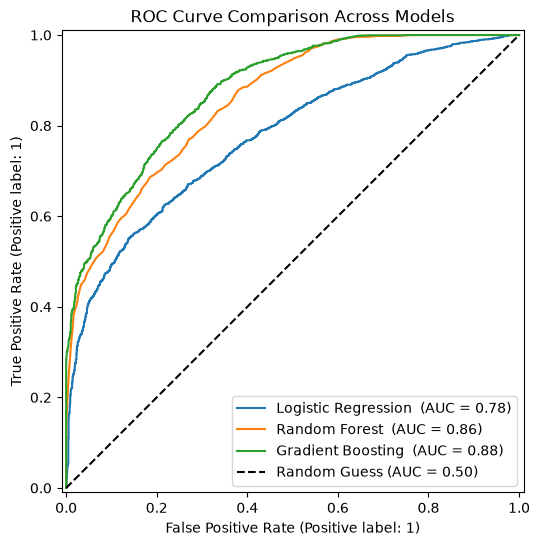

In [ ]:
# 2. Define models to compare
models = {
    "Logistic Regression": LogisticRegression(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
df_best_model = {}
y_probs_df = {}
ml_models = {}
# 3. Calculate AUC and plot ROC curves
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in models.items():
  model = model.fit(X_train[X_covariates], y_train)
  ml_models['']
  # Get probabilities for the positive class (column 1)
  y_probs = model.predict_proba(X_test[X_covariates])[:, 1]
  y_probs_df[name] = pd.Series(y_probs)

  # Calculate ROC-AUC score
  auc_score = roc_auc_score(y_test, y_probs)
  df_best_model[name] = auc_score
  print(f"{name} AUC: {auc_score:.4f}")
  
  # Plot ROC curve directly onto the shared axes
  RocCurveDisplay.from_predictions(
      y_test, y_probs, name=f"{name} ", ax=ax
  )

best_model = max(df_best_model, key=df_best_model.get)
y_probs_best_model = pd.DataFrame.from_dict(y_probs_df)[best_model]
# Add random-guess baseline
ax.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.50)")
ax.set_title("ROC Curve Comparison Across Models")
ax.legend(loc="lower right")
plt.show()

In [503]:
# 2. Compute ROC curve values
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_probs_best_model)

# 3. Calculate Youden's J statistic (TPR - FPR)
j_scores = tpr - fpr
ix = np.argmax(j_scores)
optimal_threshold = thresholds[ix]

print(f"Optimal Threshold: {optimal_threshold:.4f}")

# 4. Apply the threshold to make binary predictions
y_pred = (y_probs_best_model >= optimal_threshold).astype(int)

pd.crosstab(y_pred,y_test)

Optimal Threshold: 0.4663


BikeBuyer,0,1
Gradient Boosting,,
0,119,128
1,207,274


In [507]:
table = pd.crosstab(
    np.asarray(y_test),
    np.asarray(y_pred),
    rownames=["Actual"],
    colnames=["Predicted"],
    margins=True
)
print(table)

Predicted     0     1   All
Actual                     
0          1118   557  1675
1           220  1776  1996
All        1338  2333  3671


In [505]:
y_test.shape

(3671,)

In [506]:
metrics.confusion_matrix(y_test, y_pred, labels=[0, 1])

array([[1118,  557],
       [ 220, 1776]])

In [502]:
print("Confusion matrix:")
print(metrics.confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("Recall:", metrics.recall_score(y_test, y_pred))
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

# Compare using positional values, without pandas index alignment
print(pd.crosstab(np.asarray(y_test), np.asarray(y_pred),
                  rownames=["Actual"], colnames=["Predicted"]))

Confusion matrix:
[[1118  557]
 [ 220 1776]]
Recall: 0.8897795591182365
Accuracy: 0.7883410514846091
Predicted     0     1
Actual               
0          1118   557
1           220  1776


In [501]:
metrics.recall_score(y_test,y_pred,average='binary')

0.8897795591182365

In [497]:
metrics.accuracy_score(y_test,y_pred)

0.7883410514846091